# 04 小兔鲜儿 - 分类模块


本篇根据配套讲义 `rabbit-shop/04-分类模块.md` 整理。用户点击左侧一级分类，右侧切换到对应的二级分类和商品。

学习顺序：页面静态结构 → 分类页广告 → 获取分类树 → 一级分类高亮 → 计算当前二级分类 → 商品渲染 → 骨架屏。

复用已有能力：01 的 `http<T>`、02 的 `XtxSwiper` 和 `getHomeBannerAPI`、03 提取的 `GoodsItem`。分类接口一次返回一级分类、二级分类和商品，页面通过响应式状态完成左右联动。

资料来自[课程网盘](https://pan.baidu.com/s/1uhQQvqs9ESRvhEvgzgSUWQ?pwd=9988)，提取码 `9988`，配套包为 `02-笔记.rar`。两张教学图片直接内嵌在本篇 Notebook 中。

| 文件 | 本篇职责 |
| --- | --- |
| `src/pages/category/category.vue` | 分类页、左右滚动区域、选中下标与数据展示 |
| `src/services/category.ts` | 封装分类树接口 |
| `src/types/category.d.ts` | 一级、二级分类类型 |
| `src/pages/category/components/PageSkeleton.vue` | 分类页的骨架组件 |
| `src/services/home.ts` | 复用广告接口，传入分类页位置 `2` |
| `src/components/XtxSwiper.vue` | 复用轮播展示 |

在课程模板已有的分类页面中修改，并确认 `src/pages.json` 的分类路由和底部导航指向 `pages/category/category`。


## 准备工作

分类页由顶部搜索外观、左侧一级分类、右侧广告和二级分类商品组成。左右两栏分别使用 `scroll-view`，各自纵向滚动；顶部搜索区域留在滚动内容之外。

右侧广告继续使用公共轮播组件 `XtxSwiper`。

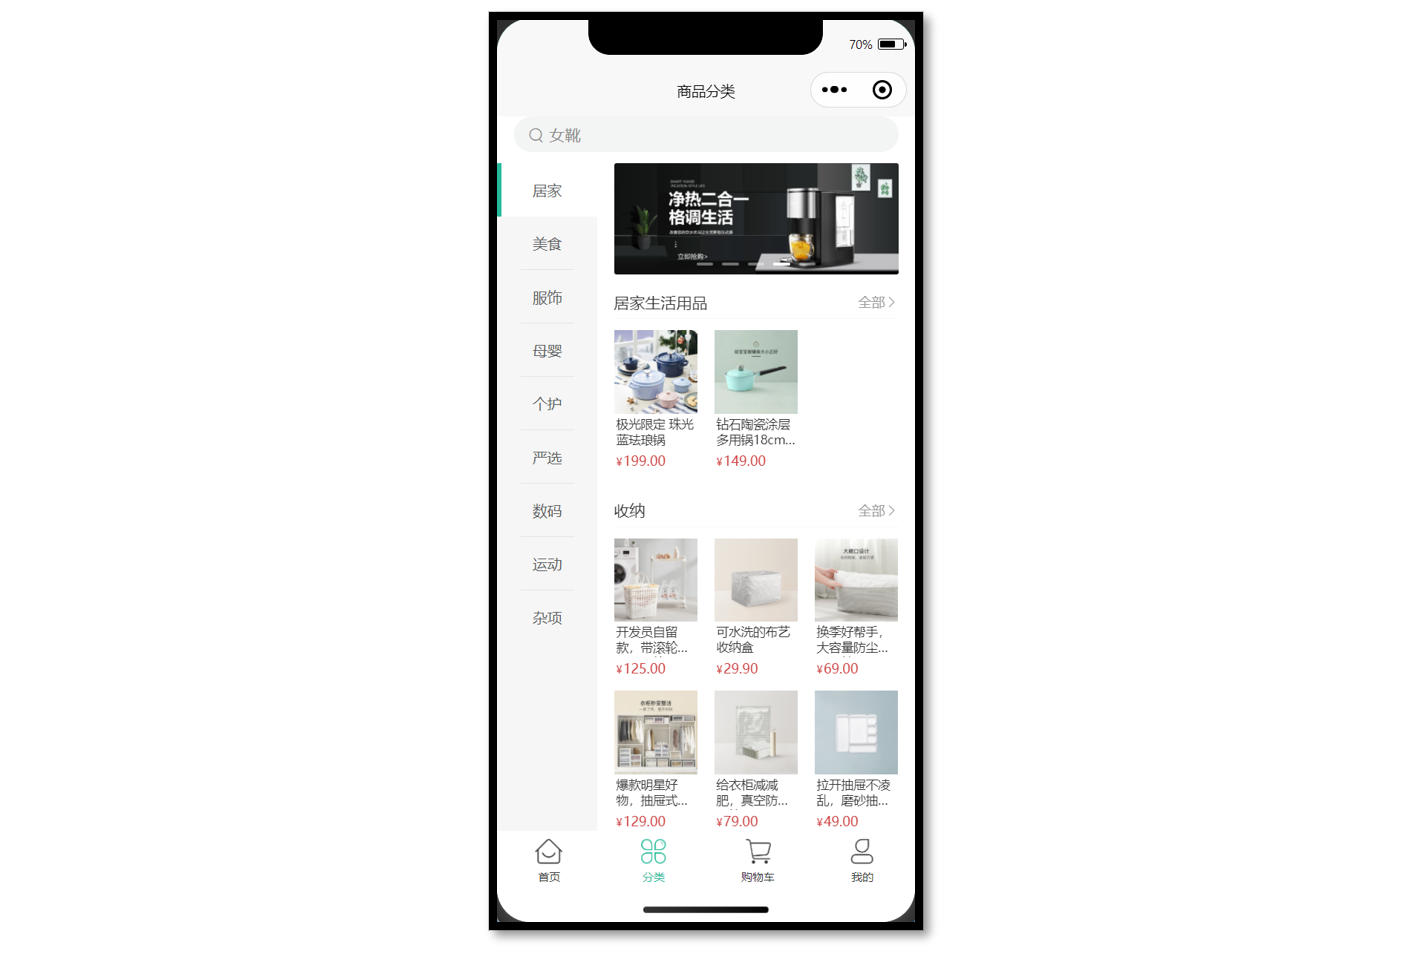


### 准备静态结构

在 `src/pages/category/category.vue` 中先准备原课的结构与样式：


```vue
<script setup lang="ts">
//
</script>

<template>
  <view class="viewport">
    <!-- 搜索框 -->
    <view class="search">
      <view class="input">
        <text class="icon-search">女靴</text>
      </view>
    </view>
    <!-- 分类 -->
    <view class="categories">
      <!-- 左侧：一级分类 -->
      <scroll-view class="primary" scroll-y>
        <view v-for="(item, index) in 10" :key="item" class="item" :class="{ active: index === 0 }">
          <text class="name"> 居家 </text>
        </view>
      </scroll-view>
      <!-- 右侧：二级分类 -->
      <scroll-view class="secondary" scroll-y>
        <!-- 焦点图 -->
        <XtxSwiper class="banner" :list="[]" />
        <!-- 内容区域 -->
        <view class="panel" v-for="item in 3" :key="item">
          <view class="title">
            <text class="name">宠物用品</text>
            <navigator class="more" hover-class="none">全部</navigator>
          </view>
          <view class="section">
            <navigator
              v-for="goods in 4"
              :key="goods"
              class="goods"
              hover-class="none"
              :url="`/pages/goods/goods?id=`"
            >
              <image
                class="image"
                src="https://yanxuan-item.nosdn.127.net/674ec7a88de58a026304983dd049ea69.jpg"
              ></image>
              <view class="name ellipsis">木天蓼逗猫棍</view>
              <view class="price">
                <text class="symbol">¥</text>
                <text class="number">16.00</text>
              </view>
            </navigator>
          </view>
        </view>
      </scroll-view>
    </view>
  </view>
</template>

<style lang="scss">
page {
  height: 100%;
  overflow: hidden;
}
.viewport {
  height: 100%;
  display: flex;
  flex-direction: column;
}
.search {
  padding: 0 30rpx 20rpx;
  background-color: #fff;
  .input {
    display: flex;
    align-items: center;
    justify-content: space-between;
    height: 64rpx;
    padding-left: 26rpx;
    color: #8b8b8b;
    font-size: 28rpx;
    border-radius: 32rpx;
    background-color: #f3f4f4;
  }
}
.icon-search {
  &::before {
    margin-right: 10rpx;
  }
}
/* 分类 */
.categories {
  flex: 1;
  min-height: 400rpx;
  display: flex;
}
/* 一级分类 */
.primary {
  overflow: hidden;
  width: 180rpx;
  flex: none;
  background-color: #f6f6f6;
  .item {
    display: flex;
    justify-content: center;
    align-items: center;
    height: 96rpx;
    font-size: 26rpx;
    color: #595c63;
    position: relative;
    &::after {
      content: '';
      position: absolute;
      left: 42rpx;
      bottom: 0;
      width: 96rpx;
      border-top: 1rpx solid #e3e4e7;
    }
  }
  .active {
    background-color: #fff;
    &::before {
      content: '';
      position: absolute;
      left: 0;
      top: 0;
      width: 8rpx;
      height: 100%;
      background-color: #27ba9b;
    }
  }
}
.primary .item:last-child::after,
.primary .active::after {
  display: none;
}
/* 二级分类 */
.secondary {
  background-color: #fff;
  .carousel {
    height: 200rpx;
    margin: 0 30rpx 20rpx;
    border-radius: 4rpx;
    overflow: hidden;
  }
  .panel {
    margin: 0 30rpx 0rpx;
  }
  .title {
    height: 60rpx;
    line-height: 60rpx;
    color: #333;
    font-size: 28rpx;
    border-bottom: 1rpx solid #f7f7f8;
    .more {
      float: right;
      padding-left: 20rpx;
      font-size: 24rpx;
      color: #999;
    }
  }
  .more {
    &::after {
      font-family: 'erabbit' !important;
      content: '\e6c2';
    }
  }
  .section {
    width: 100%;
    display: flex;
    flex-wrap: wrap;
    padding: 20rpx 0;
    .goods {
      width: 150rpx;
      margin: 0rpx 30rpx 20rpx 0;
      &:nth-child(3n) {
        margin-right: 0;
      }
      image {
        width: 150rpx;
        height: 150rpx;
      }
      .name {
        padding: 5rpx;
        font-size: 22rpx;
        color: #333;
      }
      .price {
        padding: 5rpx;
        font-size: 18rpx;
        color: #cf4444;
      }
      .number {
        font-size: 24rpx;
        margin-left: 2rpx;
      }
    }
  }
}
</style>
```

静态版本用固定次数循环确认布局，分类名称、商品图片和价格仍是示例。轮播先传空数组，保证满足组件的 `list` 属性约定。

主要样式分工：

| 选择器 | 作用 |
| --- | --- |
| `page` | 高度占满可用页面，避免整个页面在外层滚动 |
| `.viewport` | 页面纵向 flex 布局 |
| `.search` | 顶部搜索外观 |
| `.categories` | 横向排列左右分类区域，并占用剩余空间 |
| `.primary` | 左侧固定宽度 `180rpx`，不参与收缩 |
| `.primary .active` | 白色背景和左侧绿色标记 |
| `.secondary` | 右侧广告、分类标题和商品 |
| `.section` | 商品换行排列 |

`icon-search`、`ellipsis` 和 `erabbit` 图标字体沿用模板已有样式、素材。这里的搜索区域还只是展示，尚未实现输入与搜索动作。

后面的动态示例主要替换脚本与模板，**保留这段完整 SCSS**。


### 渲染分类页轮播图

广告接口仍为 `GET /home/banner`：

| 参数 | 是否必需 | 默认值 | 说明 |
| --- | --- | --- | --- |
| `distributionSite` | 否 | `1` | `1` 为首页，`2` 为商品分类页 |

分类页必须调用 `getHomeBannerAPI(2)`。直接调用不带参数的版本，会使用首页广告位置。

下列片段取自原课最后的完整代码，放在分类页的 `<script setup lang="ts">` 中。`getHomeBannerAPI` 从 `@/services/home` 导入，`BannerItem` 从 `@/types/home` 导入，`ref` 从 `vue` 导入：


```typescript
const bannerList = ref<BannerItem[]>([])
const getBannerData = async () => {
  const res = await getHomeBannerAPI(2)
  bannerList.value = res.result
}
```

取得数组后传给组件：

`<XtxSwiper class="banner" :list="bannerList" />`

父页面负责获取分类页广告，轮播组件继续负责图片、滑动和指示点。原课本篇不修改轮播的内部导航逻辑。


## 一级分类

### 获取分类树数据

分类接口为 `GET /category/top`，无请求参数。一次响应同时包含一级分类及其二级分类、商品，接下来先展示一级分类名称。

新建 `src/services/category.ts`：

> **原稿补齐**：接口片段省略了 `http` 和 `CategoryTopItem` 的导入。这里补齐实际使用的模块路径。


```typescript
// src/services/category.ts
import { http } from '@/utils/http'
import type { CategoryTopItem } from '@/types/category'
/**
 * 分类列表-小程序
 */
export const getCategoryTopAPI = () => {
  return http<CategoryTopItem[]>({
    method: 'GET',
    url: '/category/top',
  })
}
```

`http<CategoryTopItem[]>` 表示业务结果是一级分类数组；仍需通过 `res.result` 读取数组，而不是直接使用整个响应对象。


### 声明一级与二级分类类型

新建 `src/types/category.d.ts`，使用 03 已提取的通用商品类型：


```typescript
// src/types/category.d.ts
import type { GoodsItem } from './global'

/** 一级分类项 */
export type CategoryTopItem = {
  /** 二级分类集合[ 二级分类项 ] */
  children: CategoryChildItem[]
  /** 一级分类id */
  id: string
  /** 一级分类图片集[ 一级分类图片项 ] */
  imageBanners: string[]
  /** 一级分类名称 */
  name: string
  /** 一级分类图片 */
  picture: string
}

/** 二级分类项 */
export type CategoryChildItem = {
  /** 商品集合[ 商品项 ] */
  goods: GoodsItem[]
  /** 二级分类id */
  id: string
  /** 二级分类名称 */
  name: string
  /** 二级分类图片 */
  picture: string
}
```

数据结构按层次展开：

| 数据 | 位置 |
| --- | --- |
| 全部一级分类 | `CategoryTopItem[]` |
| 某一级分类的二级分类 | `CategoryTopItem.children` |
| 某二级分类的商品 | `CategoryChildItem.goods` |
| 单件商品字段 | `GoodsItem` |

一级分类中的 `imageBanners` 和 `picture` 是接口声明的字段；本篇右侧轮播使用独立的 `/home/banner` 广告接口，并没有改为使用 `imageBanners`。

这里的类型描述响应结构，不会自动加载或转换数据。


### 渲染左侧列表并切换高亮

在分类页中保存列表和当前选中下标：


```vue
<script setup lang="ts">
import { getCategoryTopAPI } from '@/services/category'
import type { CategoryTopItem } from '@/types/category'
import { onLoad } from '@dcloudio/uni-app'
import { ref } from 'vue'

// 获取分类列表数据
const categoryList = ref<CategoryTopItem[]>([])
const getCategoryTopData = async () => {
  const res = await getCategoryTopAPI()
  categoryList.value = res.result
}

// 高亮下标
const activeIndex = ref(0)

// 页面加载
onLoad(() => {
  getCategoryTopData()
})
</script>

<template>
  <view class="viewport">
    <!-- 分类 -->
    <view class="categories">
      <!-- 左侧：一级分类 -->
      <scroll-view class="primary" scroll-y>
        <view
          class="item"
          v-for="(item, index) in categoryList"
          :key="item.id"
          :class="{ active: index === activeIndex }"
          @tap="activeIndex = index"
        >
          {{ item.name }}
        </view>
      </scroll-view>
    </view>
  </view>
</template>
```

这是一级分类阶段的局部页面，稍后与搜索、右侧区域和轮播合并。`onLoad` 调用接口，把响应数组写入 `categoryList`。

左侧循环使用 `item.id` 作为 key，以 `index === activeIndex` 决定高亮；点击时更新 `activeIndex`。初始值 `0` 表示默认选中第一个一级分类。

脚本中 ref 需要通过 `.value` 读写，模板里自动解包，因此 `@tap="activeIndex = index"` 可以直接赋值。


## 二级分类

二级分类从属于某个一级分类，当前展示的数据由“全部分类树 + 选中下标”决定。使用 `computed` 提取当前一级分类的 `children`，无需再手动维护另一份同步列表。

计算关系为：

`subCategoryList = categoryList[activeIndex]?.children || []`

当 `categoryList` 首次加载完成，或 `activeIndex` 在点击后变化时，计算属性会重新得到当前的二级分类。

`?.children` 与 `|| []` 处理初始空列表、下标暂时没有对应数据的情况，让模板可以安全地遍历空数组。


### 渲染右侧二级分类与商品

下面是原课右侧区域片段，继续使用前面已定义的 `categoryList`、`activeIndex` 和 `bannerList`：

> **原稿结构补齐**：原片段省略了 `categories` 的开始标签，却保留了结束标签。这里补齐该层容器，使显示出来的模板标签成对闭合；左侧一级分类内容仍以注释省略。


```vue
<script setup lang="ts">
import { computed } from 'vue'

// ...省略

// 提取当前二级分类数据
const subCategoryList = computed(() => {
  return categoryList.value[activeIndex.value]?.children || []
})
</script>

<template>
  <view class="viewport">
    <view class="categories">
      <!-- 左侧一级分类等内容省略 -->
      <!-- 右侧：二级分类 -->
      <scroll-view class="secondary" scroll-y>
        <!-- 焦点图 -->
        <XtxSwiper class="banner" :list="bannerList" />
        <!-- 内容区域 -->
        <view class="panel" v-for="item in subCategoryList" :key="item.id">
          <view class="title">
            <text class="name">{{ item.name }}</text>
            <navigator class="more" hover-class="none">全部</navigator>
          </view>
          <view class="section">
            <navigator
              v-for="goods in item.goods"
              :key="goods.id"
              class="goods"
              hover-class="none"
              :url="`/pages/goods/goods?id=${goods.id}`"
            >
              <image class="image" :src="goods.picture"></image>
              <view class="name ellipsis">{{ goods.name }}</view>
              <view class="price">
                <text class="symbol">¥</text>
                <text class="number">{{ goods.price }}</text>
              </view>
            </navigator>
          </view>
        </view>
      </scroll-view>
    </view>
  </view>
</template>
```

先遍历 `subCategoryList` 显示二级分类标题，再遍历每项的 `goods` 显示商品图片、名称和价格。商品导航携带实际 `goods.id`，指向后续实现的详情页。

“全部”入口在本篇只有展示结构，原稿尚未给它配置跳转地址。点击一级分类的当前实现只切换内容，没有增加右侧滚动位置重置逻辑。

**跟做检查**：点击几个不同一级分类，确认左侧高亮、右侧二级分类标题和商品同时切换；再次切回时，数据来自已经获取的分类树，不需要为这次切换额外请求分类接口。


## 骨架屏

分类列表和广告正在加载时，先显示与分类页结构相近的灰色占位，数据准备好后再显示真实页面。

原课要求参考 02 首页骨架屏的生成方式；分类页的骨架内容应按本页布局生成。

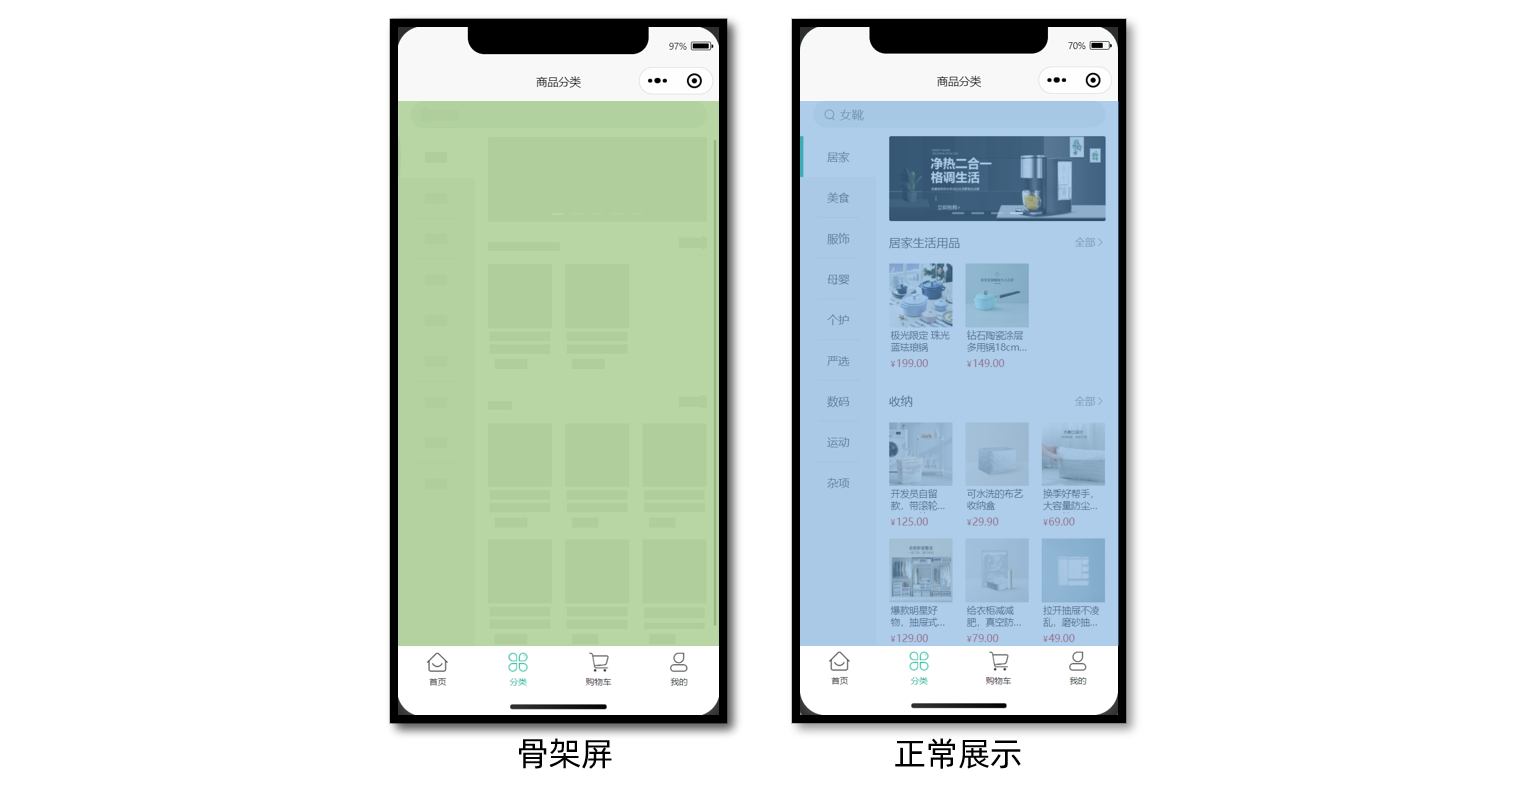


### 封装分类页骨架并控制显示

按 02 的方法操作：

1. 先在微信开发者工具中运行能展示真实数据的分类页。
2. 通过“页面信息 → 生成骨架屏”取得结构与样式。
3. 整理生成的 WXML、WXSS 为 `src/pages/category/components/PageSkeleton.vue`。
4. 在分类页显式导入这个业务组件，再根据加载状态切换。

原资料没有提供分类骨架组件的完整文本，需要根据自己的分类页生成；这里保留原课效果图和实际接入代码。

本篇使用 `isFinish` 表示广告与分类数据是否准备完成，初始为 `false`。通过 `Promise.all` 同时等待 `getBannerData()` 与 `getCategoryTopData()`；两者成功后才设为 `true`。

模板中真实页面使用 `v-if="isFinish"`，紧随其后的 `PageSkeleton` 使用 `v-else`。这里的 `isFinish` 是首次数据准备状态，不是 02、03 中的分页结束标记。

> **原课边界**：此处没有为请求失败单独设置页面状态。任意请求拒绝时，`isFinish` 不会变成 `true`，页面仍显示骨架。01 的请求封装会提供错误提示，但它不会替分类页切换加载状态。


## 代码参考（总）

下面保留原课分类页的完整脚本和模板，合并到 `src/pages/category/category.vue`。仍使用前面静态结构的完整 SCSS，并先准备好本页的 `components/PageSkeleton.vue`。

之前分步骤展示的 `categoryList`、`activeIndex`、`computed`、`onLoad` 和轮播数据逻辑已经包含在这里，不要重复保留两份脚本。


```vue
<script setup lang="ts">
import { getCategoryTopAPI } from '@/services/category'
import { getHomeBannerAPI } from '@/services/home'
import type { CategoryTopItem } from '@/types/category'
import type { BannerItem } from '@/types/home'
import { onLoad } from '@dcloudio/uni-app'
import { computed, ref } from 'vue'
import PageSkeleton from './components/PageSkeleton.vue'

// 获取轮播图数据
const bannerList = ref<BannerItem[]>([])
const getBannerData = async () => {
  const res = await getHomeBannerAPI(2)
  bannerList.value = res.result
}

// 获取分类列表数据
const categoryList = ref<CategoryTopItem[]>([])
const activeIndex = ref(0)
const getCategoryTopData = async () => {
  const res = await getCategoryTopAPI()
  categoryList.value = res.result
}

// 是否数据加载完毕
const isFinish = ref(false)
// 页面加载
onLoad(async () => {
  await Promise.all([getBannerData(), getCategoryTopData()])
  isFinish.value = true
})

// 提取当前二级分类数据
const subCategoryList = computed(() => {
  return categoryList.value[activeIndex.value]?.children || []
})
</script>

<template>
  <view class="viewport" v-if="isFinish">
    <!-- 搜索框 -->
    <view class="search">
      <view class="input">
        <text class="icon-search">女靴</text>
      </view>
    </view>
    <!-- 分类 -->
    <view class="categories">
      <!-- 左侧：一级分类 -->
      <scroll-view class="primary" scroll-y>
        <view
          v-for="(item, index) in categoryList"
          :key="item.id"
          class="item"
          :class="{ active: index === activeIndex }"
          @tap="activeIndex = index"
        >
          <text class="name">
            {{ item.name }}
          </text>
        </view>
      </scroll-view>
      <!-- 右侧：二级分类 -->
      <scroll-view class="secondary" scroll-y>
        <!-- 焦点图 -->
        <XtxSwiper class="banner" :list="bannerList" />
        <!-- 内容区域 -->
        <view class="panel" v-for="item in subCategoryList" :key="item.id">
          <view class="title">
            <text class="name">{{ item.name }}</text>
            <navigator class="more" hover-class="none">全部</navigator>
          </view>
          <view class="section">
            <navigator
              v-for="goods in item.goods"
              :key="goods.id"
              class="goods"
              hover-class="none"
              :url="`/pages/goods/goods?id=${goods.id}`"
            >
              <image class="image" :src="goods.picture"></image>
              <view class="name ellipsis">{{ goods.name }}</view>
              <view class="price">
                <text class="symbol">¥</text>
                <text class="number">{{ goods.price }}</text>
              </view>
            </navigator>
          </view>
        </view>
      </scroll-view>
    </view>
  </view>
  <!-- 骨架屏 -->
  <PageSkeleton v-else />
</template>
```

完整流程：

1. 页面加载，广告和分类树两个请求同时发起。
2. 请求结果分别保存在 `bannerList`、`categoryList`。
3. 两个请求成功后显示真实页面。
4. 默认显示第一个一级分类的 `children`。
5. 用户点击左侧，只更新 `activeIndex`。
6. `subCategoryList` 跟随计算，右侧模板显示对应二级分类和商品。

本篇分类展示没有触底分页参数；商品直接来自各二级分类的 `goods` 数组。


## 本篇完成检查

- [ ] 分类页结构和完整 SCSS 已保留，左右区域分别能够纵向滚动。
- [ ] 广告接口传入 `distributionSite = 2`，数据已传给 `XtxSwiper`。
- [ ] 分类服务的公共请求函数、数据类型导入完整。
- [ ] 一级分类名称来自接口，默认高亮第一项。
- [ ] 点击一级分类后，高亮和右侧二级分类、商品同步变化。
- [ ] 分类数据为空时，计算属性返回空数组。
- [ ] 商品卡片带真实商品 ID，“全部”和搜索仍按本篇阶段保留展示结构。
- [ ] 广告与分类树都加载成功后，骨架屏切换为真实内容。

本篇完成分类页数据展示、左右联动和骨架屏，后续继续实现商品详情。
